# Hourly Electricity Consumption: Time Curve and Distribution

This notebook explores hourly electricity use during the **training period (January–August 2013)** for households assigned to the **DEVELOPMENT** split.

**Outputs:** `figures/hourly_consumption.png`, `figures/hourly_distribution.png`, and `figures/consumption_chart_notes.md`.

Run the cells in order. Paths assume the notebook is located **two directory levels beneath the project root**, matching the original code.

## 1. Import libraries and configure paths

Use **pandas** for data loading/filtering and **Matplotlib** for the charts. Create the figure directory if needed.

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# This notebook is intended to run from notebooks/<subfolder>/, as in the original scripts.
PROJECT_ROOT = Path("../..").resolve()
HOURLY_PATH = PROJECT_ROOT / "data/processed/hourly_readings.csv"
SPLIT_PATH = PROJECT_ROOT / "data/household_split.csv"
OUT_DIR = PROJECT_ROOT / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load hourly readings and household splits

Convert timestamps to timezone-aware **UTC** values and energy readings to numeric values. Non-numeric energy values become missing (`NaN`). Keep only households marked `DEVELOPMENT` (case-insensitive).

In [7]:
hourly = pd.read_csv(HOURLY_PATH)
hourly["hour_start"] = pd.to_datetime(hourly["hour_start"], utc=True)
hourly["kWh"] = pd.to_numeric(hourly["kWh"], errors="coerce")

splits = pd.read_csv(SPLIT_PATH)
dev_homes = splits.loc[
    splits["Cohort"].str.upper() == "DEVELOPMENT", "LCLid"
].tolist()

if not dev_homes:
    raise ValueError("No DEVELOPMENT households were found in household_split.csv")

print(f"Loaded {len(hourly):,} hourly rows and {len(dev_homes):,} development households.")

Loaded 2,628,000 hourly rows and 240 development households.


## 3. Select development households and training dates

The training window is **2013-01-01 inclusive through 2013-09-01 exclusive**. The exclusive upper bound includes all of August without including September.

In [8]:
train_start = pd.Timestamp("2013-01-01", tz="UTC")
train_end = pd.Timestamp("2013-09-01", tz="UTC")

train_data = hourly.loc[
    hourly["LCLid"].isin(dev_homes)
    & (hourly["hour_start"] >= train_start)
    & (hourly["hour_start"] < train_end)
].copy()

print(f"Training rows: {len(train_data):,}")

Training rows: 1,399,680


## 4. Plot a two-week time curve for one household

Use the first development household and display its hourly `kWh` observations from **January 1 up to (but not including) January 15, 2013**. Missing recorded values appear as breaks in the line. The count below covers `NaN` values in **existing rows**; absent timestamp rows are not counted.

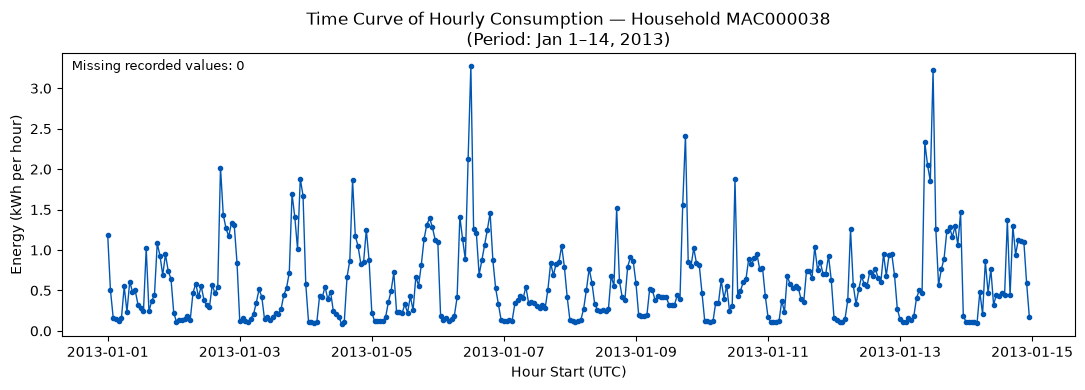

In [9]:
sample_home = dev_homes[0]
short_window_end = train_start + pd.Timedelta(days=14)

home_curve = train_data.loc[
    (train_data["LCLid"] == sample_home)
    & (train_data["hour_start"] < short_window_end)
].sort_values("hour_start")

missing_hrs = home_curve["kWh"].isna().sum()

fig1, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(home_curve["hour_start"], home_curve["kWh"], marker=".", linewidth=1, color="#0056b3")
ax1.set_title(
    f"Time Curve of Hourly Consumption — Household {sample_home}\n"
    "(Period: Jan 1–14, 2013)"
)
ax1.set_xlabel("Hour Start (UTC)")
ax1.set_ylabel("Energy (kWh per hour)")
ax1.text(0.01, 0.98, f"Missing recorded values: {missing_hrs}",
         transform=ax1.transAxes, va="top", fontsize=9)
fig1.tight_layout()
fig1.savefig(OUT_DIR / "hourly_consumption.png", dpi=150)
plt.show()

## 5. Plot the distribution of training-period consumption

Combine the valid hourly values from **all development households** and display a 50-bin histogram. Missing (`NaN`) values are excluded from the histogram and reported separately.

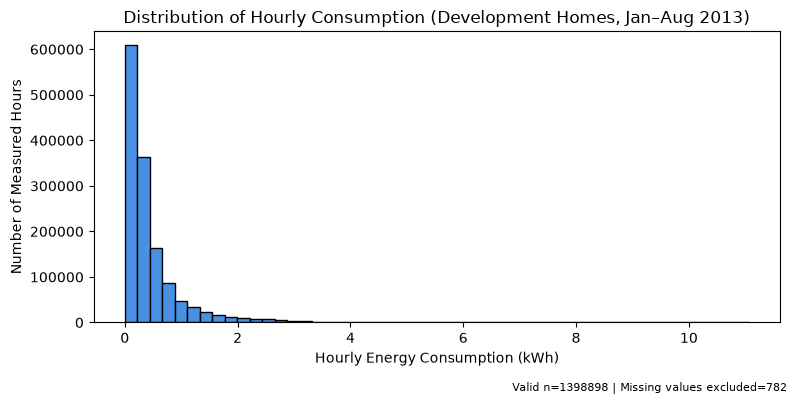

In [10]:
valid_kwh = train_data["kWh"].dropna()
total_missing = train_data["kWh"].isna().sum()

fig2, ax2 = plt.subplots(figsize=(8, 4))
ax2.hist(valid_kwh, bins=50, edgecolor="black", color="#4A90E2")
ax2.set_title("Distribution of Hourly Consumption (Development Homes, Jan–Aug 2013)")
ax2.set_xlabel("Hourly Energy Consumption (kWh)")
ax2.set_ylabel("Number of Measured Hours")
fig2.text(0.99, 0.01,
          f"Valid n={len(valid_kwh)} | Missing values excluded={total_missing}",
          ha="right", fontsize=8)
fig2.tight_layout(rect=[0, 0.035, 1, 1])
fig2.savefig(OUT_DIR / "hourly_distribution.png", dpi=150)
plt.show()

## 6. Export chart notes

Create a Markdown file containing descriptions and basic coverage statistics that can be reused in a report.

In [11]:
captions = (
    "# M5 Week 2 Charts\n\n"
    "## Hourly Consumption Curve\n"
    f"Household {sample_home}, Jan 1–14, 2013 (TRAIN period). Energy is kWh per hour. "
    f"There are {missing_hrs} missing values in recorded rows during this window "
    "(shown as gaps). Absent timestamp rows are not counted.\n\n"
    "## Hourly Distribution\n"
    f"Development homes (n={len(dev_homes)}), TRAIN period (Jan–Aug 2013). "
    f"{len(valid_kwh)} valid hourly readings in kWh. "
    f"Missing recorded values excluded: {total_missing}."
)
notes_path = OUT_DIR / "consumption_chart_notes.md"
notes_path.write_text(captions, encoding="utf-8")
print(f"Saved plots and notes to: {OUT_DIR}")

Saved plots and notes to: C:\Projects\Data mining project\household-energy-prediction\figures
